In [1]:
import os
import sys
from datetime import date, datetime

# import torch
# from torch.func import jacrev
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pytz

In [2]:
import os
import sys

os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"
os.environ["QUANTDATA_TRAINING_DATA"] = "!/quantdata/training"
os.environ["QUANTDATA_PROCESSING_DATA"] = "!/quantdata/processing"
os.environ["MASSIVE_TOKEN"] = "jsnt7igBpyyAduX4WGdDEuw0gStWNVFk"
os.environ["QUANTDATA_TEST_MODE"] = "0"
os.environ["QUANTDATA_CACHE_MODE"] = "on"  # turns off global cache mode

import importlib as imp

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")

if project_root not in sys.path:
    sys.path.insert(0, project_root)
import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

from datetime import date

from quantdata.massive.options.contracts import (
    Context,
    ContractsFilter,
    DateRange,
    PoolConfig,
    filter_contracts,
    filter_contracts_between,
)


def test_contracts():
    date_range = DateRange(start=date(2024, 1, 5), end=date(2024, 1, 5), exclude_half_days=True)
    pool_config = PoolConfig(num_workers=8, threading=False)
    contracts_filter = ContractsFilter(max_dte=25, max_mns=3.0, min_opt_vol_k=1)

    return filter_contracts_between(
        "SPY",
        date_range,
        contracts_filter=contracts_filter,
        override_cache_mode=None,
        refresh=False,
        pool_config=pool_config,
        verbose=Context.all,
    )


df = test_contracts()

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:152: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


00: Filtering contracts for SPY on 2024-01-05 ... 0% done.
01:   Fetching all contracts for SPY expiring on or after 2024-01-05... found 2838 contracts. This took 0.79s.


/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:152: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.
/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:152: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.
/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:152: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.
/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:152: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.
/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:152: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.
/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:152: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.
/Users/elie/Documents/GitHub/quant

01:   Filtered 2,838 contacts for SPY on 2024-01-05, yielding 390 active contracts. This took 1:13. Timing: Prep: 0.00s, Fetch open close volume prev: 0.14s, Fetch quotes & trades: 0.46s, Fetch open close volume today: 0.13s.
00: Concatenating 1 contracts for SPY from 2024-01-05 to 2024-01-05... 00: done. This took 0.011ms.


In [3]:
tickers_day = df.filter(pl.col("ticker").str.contains("SPY240105")).select(["ticker"]).unique()

In [4]:
project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")

if project_root not in sys.path:
    sys.path.insert(0, project_root)


os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"  # better set these to environment variables
os.environ["QUANTDATA_TRAINING_DATA"] = (
    "!/quantdata/training"  # better set these to environment variables
)
os.environ["QUANTDATA_PROCESSING_DATA"] = (
    "!/quantdata/processing"  # better set these to environment variables
)
os.environ["QUANTDATA_CACHE_MODE"] = "on"  # turns off global cache mode
os.environ["QUANTDATA_TEST_MODE"] = "0"
import importlib as imp

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

from datetime import date

from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context

from quantdata.massive.client import MassiveClient


def test_get_option(option_ticker):

    ticker = "SPY"
    d = date(2024, 1, 3)
    client = MassiveClient()

    def package(ticker, verbose=Context.all):

        with verbose.write_t(
            f"Fetching OCV, trades, quotes for {ticker} on {fmt_date(d)}... ", end=""
        ) as tme:
            ocv = client.fetch_day_summary(ticker, d, adjusted=True)
            verbose.write(f"done: found {fmt_dict(ocv)}. This took {tme}.", head=False)

        with verbose.write_t(f"Fetching trades for {ticker} on {fmt_date(d)}... ", end="") as tme:
            trades = client.fetch_trades(ticker, d)
            verbose.write(f"done: found {len(trades)} trades. This took {tme}.", head=False)

        with verbose.write_t(f"Fetching quotes for {ticker} on {fmt_date(d)}... ", end="") as tme:
            quotes = client.fetch_quotes(ticker, d)
            verbose.write(f"done: found {len(quotes)} quotes. This took {tme}.", head=False)

        return ocv, trades, quotes

    package(ticker)
    ocv, trades, quotes = package(option_ticker)

    # display(ocv)
    # display(trades.head())
    # display(quotes.head())

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:152: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [5]:
import contextlib
import io

total_tickers = len(tickers_day)
ticker_counter = 0
failed_tickers = set()
print(f"Processing {total_tickers} tickers...")
for ticker in tickers_day["ticker"]:
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            test_get_option(ticker)
        ticker_counter += 1
        print(f"Finished processing {ticker_counter}/{total_tickers}.")
    except Exception as e:
        print(f"Error processing {ticker}: {e}")
        failed_tickers.add(ticker)
        ticker_counter += 1
        continue

Processing 404 tickers...
Finished processing 1/404.
Error processing O:SPY240105C00345000: No open/close/volume for O:SPY240105C00345000 on 2024-01-03 url https://api.massive.com/v1/open-close/O:SPY240105C00345000/2024-01-03: {"status":"NOT_FOUND","request_id":"4c78298df13e41898a24a9a24234c875","message":"Data not found."}
Error processing O:SPY240105P00329000: No open/close/volume for O:SPY240105P00329000 on 2024-01-03 url https://api.massive.com/v1/open-close/O:SPY240105P00329000/2024-01-03: {"status":"NOT_FOUND","request_id":"f1a0aaa07a43dd53e2d6a992a8e1151f","message":"Data not found."}
Error processing O:SPY240105C00412000: No open/close/volume for O:SPY240105C00412000 on 2024-01-03 url https://api.massive.com/v1/open-close/O:SPY240105C00412000/2024-01-03: {"status":"NOT_FOUND","request_id":"212223d570a3c965b809d9aef81cc2df","message":"Data not found."}
Error processing O:SPY240105C00370000: No open/close/volume for O:SPY240105C00370000 on 2024-01-03 url https://api.massive.com/v

In [6]:
failed_tickers

{'O:SPY240105C00275000',
 'O:SPY240105C00280000',
 'O:SPY240105C00285000',
 'O:SPY240105C00290000',
 'O:SPY240105C00295000',
 'O:SPY240105C00300000',
 'O:SPY240105C00305000',
 'O:SPY240105C00310000',
 'O:SPY240105C00315000',
 'O:SPY240105C00320000',
 'O:SPY240105C00325000',
 'O:SPY240105C00326000',
 'O:SPY240105C00327000',
 'O:SPY240105C00328000',
 'O:SPY240105C00329000',
 'O:SPY240105C00330000',
 'O:SPY240105C00331000',
 'O:SPY240105C00332000',
 'O:SPY240105C00333000',
 'O:SPY240105C00334000',
 'O:SPY240105C00335000',
 'O:SPY240105C00336000',
 'O:SPY240105C00337000',
 'O:SPY240105C00338000',
 'O:SPY240105C00339000',
 'O:SPY240105C00340000',
 'O:SPY240105C00341000',
 'O:SPY240105C00342000',
 'O:SPY240105C00343000',
 'O:SPY240105C00344000',
 'O:SPY240105C00345000',
 'O:SPY240105C00346000',
 'O:SPY240105C00347000',
 'O:SPY240105C00348000',
 'O:SPY240105C00349000',
 'O:SPY240105C00350000',
 'O:SPY240105C00351000',
 'O:SPY240105C00352000',
 'O:SPY240105C00353000',
 'O:SPY240105C00354000',


In [14]:
tickers_day = tickers_day.with_columns(pl.col("ticker").is_in(failed_tickers).alias("option_error"))

In [15]:
tickers_day

ticker,option_error
str,bool
"""O:SPY240105C00491000""",false
"""O:SPY240105C00345000""",true
"""O:SPY240105P00329000""",true
"""O:SPY240105C00412000""",true
"""O:SPY240105C00370000""",true
…,…
"""O:SPY240105P00457500""",false
"""O:SPY240105C00441000""",false
"""O:SPY240105C00331000""",true


In [16]:
df_tickers = tickers_day.filter(pl.col("option_error") == False).sort("ticker").select("ticker")

In [17]:
client = MassiveClient()

trade_counts = [
    client.fetch_trades(ticker, date(2024, 1, 3)).shape[0] for ticker in df_tickers["ticker"]
]

df_tickers = df_tickers.with_columns(pl.Series("trade_count", trade_counts))

In [18]:
df_tickers = df_tickers.with_columns(
    pl.col("ticker").str.slice(-6).cast(pl.Float64).alias("ticker_suffix")
)

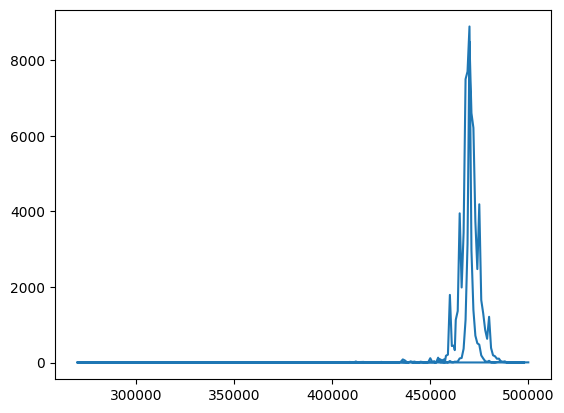

In [19]:
plt.plot(df_tickers["ticker_suffix"], df_tickers["trade_count"].to_list())

In [20]:
df_tickers.write_csv("spy_options_tickers.csv")